# Tongji：原始数据、预处理与随机训练样本审查

每次 **Run All** 都会生成新随机种子，并随机选择一颗电芯及循环。重新运行“随机选择”及之后的单元也可以换一颗电芯。

预处理命令（项目根目录）：`uv run python scripts/preprocess_tongji.py --output data/tongji_v1`。输出目录必须不存在，避免覆盖已有结果。

数据保留物理单位；温度缺失不补造测量值；SOH = 有效完整放电容量 / 额定容量。充电片段来自正电流的最长连续区间，提取阈值与标签审查规则见 `schema.json`。

本 Notebook 只读原始数据和预处理文件；下文的完整未来曲线仅用于人工核对，不作为 Dataset 输入。

In [3]:
from pathlib import Path
import sys, json, pickle
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from IPython.display import display, HTML
from torch.utils.data import DataLoader


%cd "D:\Coding\projects\BatteryLifePrediction"

DATA = Path("data/tongji_v1")
schema = json.loads((DATA / "schema.json").read_text(encoding="utf-8"))
manifest = json.loads((DATA / "manifest.json").read_text(encoding="utf-8"))
assert manifest["complete"]
features = schema["features"]
print("Project:", Path.cwd())
print("Cells:", len(manifest["cells"]))

D:\Coding\projects\BatteryLifePrediction
Project: D:\Coding\projects\BatteryLifePrediction
Cells: 130


In [4]:
ARRAY_NAMES = (
    "values",
    "value_valid",
    "time_in_cycle",
    "raw_sample_index",
    "cycle_offsets",
    "cycle_id",
    "static_categorical",
    "static_numeric",
    "static_valid",
    "conditions",
    "conditions_valid",
    "soh",
    "soh_valid",
)


def load_cell(directory):
    """Memory-map one preprocessed cell; never alter these arrays in place."""
    directory = Path(directory)
    return {
        name: np.load(directory / f"{name}.npy", mmap_mode="r", allow_pickle=False)
        for name in ARRAY_NAMES
    }

## 1. 随机选择与文件结构

默认使用系统熵生成种子；记录下输出的 seed 后，可以手动将 `seed = ...` 固定为某个整数来复现审查。

In [9]:
seed = int(np.random.SeedSequence().generate_state(1)[0])
rng = np.random.default_rng(seed)

# 随机选一个 cell 并读取所有 numpy 数据
cell_id = str(rng.choice([c["cell_id"] for c in manifest["cells"]]))
cell_dir = DATA / "cells" / cell_id
cell = load_cell(cell_dir)

# 读取 metadata 以及原始电池对象
metadata = json.loads((cell_dir / "metadata.json").read_text(encoding="utf-8"))
raw_path = Path("raw_data/Tongji") / metadata["source_file"]
with raw_path.open("rb") as stream:
    raw = pickle.load(stream)


raw_by_id = {int(c["cycle_number"]): c for c in raw["cycle_data"]}
lengths = np.diff(cell["cycle_offsets"])
row = int(rng.choice(np.flatnonzero(lengths >= 8)))
cycle_id = int(cell["cycle_id"][row])
start, end = cell["cycle_offsets"][row : row + 2]
original = raw_by_id[cycle_id]

print("seed:", seed, "cell:", cell_id, "cycle:", cycle_id)
print(
    "raw cycle points:",
    len(original["current_in_A"]),
    "charge points:",
    int(end - start),
)
for name, arr in cell.items():
    print(f"{name:24} shape={str(arr.shape):18} dtype={arr.dtype}")
print("Static raw:", json.dumps(metadata["static_raw"], ensure_ascii=False, indent=2))
print("Conditions:", dict(zip(schema["conditions"], cell["conditions"][row].tolist())))
print("Invalid label cycles:", metadata["label_issues"])


seed: 1821495972 cell: Tongji2_CY25-05_1--7 cycle: 43
raw cycle points: 903 charge points: 566
values                   shape=(101378, 5)        dtype=float32
value_valid              shape=(101378, 5)        dtype=bool
time_in_cycle            shape=(101378,)          dtype=float64
raw_sample_index         shape=(101378,)          dtype=int64
cycle_offsets            shape=(193,)             dtype=int64
cycle_id                 shape=(192,)             dtype=int64
static_categorical       shape=(5,)               dtype=int64
static_numeric           shape=(3,)               dtype=float32
static_valid             shape=(8,)               dtype=bool
conditions               shape=(192, 4)           dtype=float32
conditions_valid         shape=(192, 4)           dtype=bool
soh                      shape=(192,)             dtype=float32
soh_valid                shape=(192,)             dtype=bool
Static raw: {
  "form_factor": "cylindrical_18650",
  "cathode_material": "Li0.84(Ni0.83Co0.1

## 2. 原始完整循环与提取出的充电段

灰线为原始完整循环，橙线为保留的充电段。时间相对完整循环起点计算。缺失温度明确显示为空缺，不绘制占位零值。

逐点检查利用 `raw_sample_index.npy` 回查原始记录，确认预处理没有插值、改变测量值或重新编号循环。

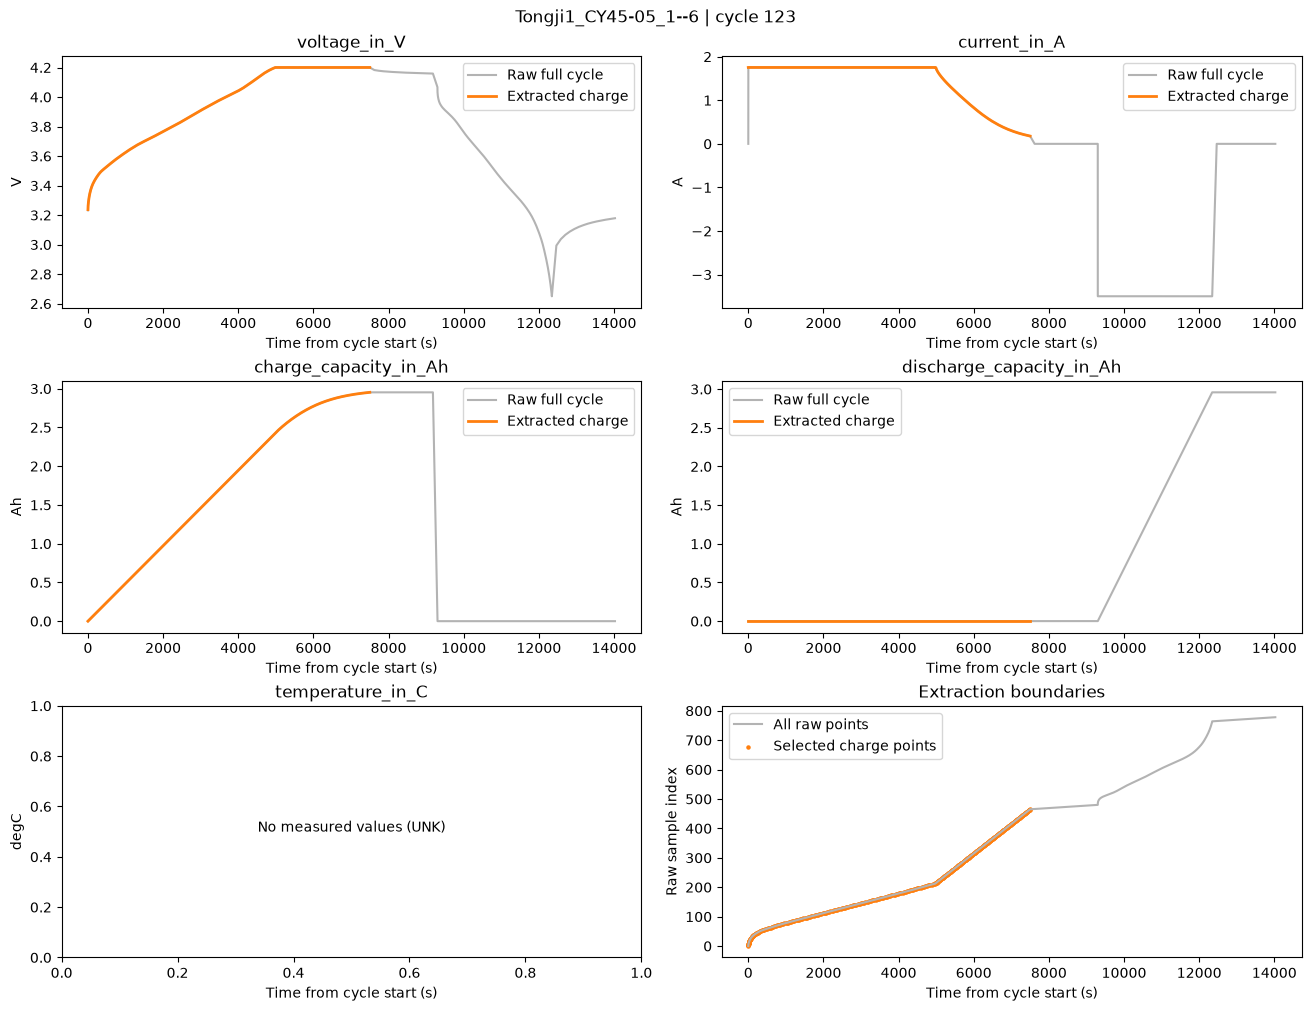

Raw-to-processed checks passed


In [ ]:
source_index = cell["raw_sample_index"][start:end]
processed_time = cell["time_in_cycle"][start:end]
raw_time = np.asarray(original["time_in_s"], float)
raw_time = raw_time - raw_time[0]
np.testing.assert_allclose(processed_time, raw_time[source_index])
fig, axes = plt.subplots(3, 2, figsize=(13, 10), constrained_layout=True)
for f, ax in enumerate(axes.flat[:5]):
    key = features[f]
    value = original.get(key)
    valid = cell["value_valid"][start:end, f]
    if value is not None:
        array = np.asarray(value, float)
        ax.plot(raw_time, array, color="0.7", label="Raw full cycle")
        np.testing.assert_allclose(
            cell["values"][start:end, f][valid],
            array[source_index][valid],
            rtol=2e-6,
            atol=1e-7,
        )
    if valid.any():
        ax.plot(
            processed_time[valid],
            cell["values"][start:end, f][valid],
            color="tab:orange",
            linewidth=2,
            label="Extracted charge",
        )
        ax.legend()
    else:
        ax.text(
            0.5, 0.5, "No measured values (UNK)", ha="center", transform=ax.transAxes
        )
    ax.set(
        title=key, xlabel="Time from cycle start (s)", ylabel=schema["feature_units"][f]
    )
ax = axes.flat[5]
ax.plot(raw_time, np.arange(len(raw_time)), color="0.7", label="All raw points")
ax.scatter(
    processed_time,
    source_index,
    s=5,
    color="tab:orange",
    label="Selected charge points",
)
ax.set(
    xlabel="Time from cycle start (s)",
    ylabel="Raw sample index",
    title="Extraction boundaries",
)
ax.legend()
fig.suptitle(f"{cell_id} | cycle {cycle_id}")
plt.show()
print("Raw-to-processed checks passed")


## 3. 容量标签与天然缺失

有效标签是完整放电记录的正累计容量最大值除以额定容量；要求计数器起点接近零、未明显回退，并达到放电截止电压（容差见 schema）。不符合规则的标签保留循环，但 `soh_valid=False`。该规则是可审查的筛选，不代表独立物理测量验证。

工况温度来自实验协议，不是缺失的实测温度通道。处理后的时间可能经过上游压缩，不能作为原始静置时长。

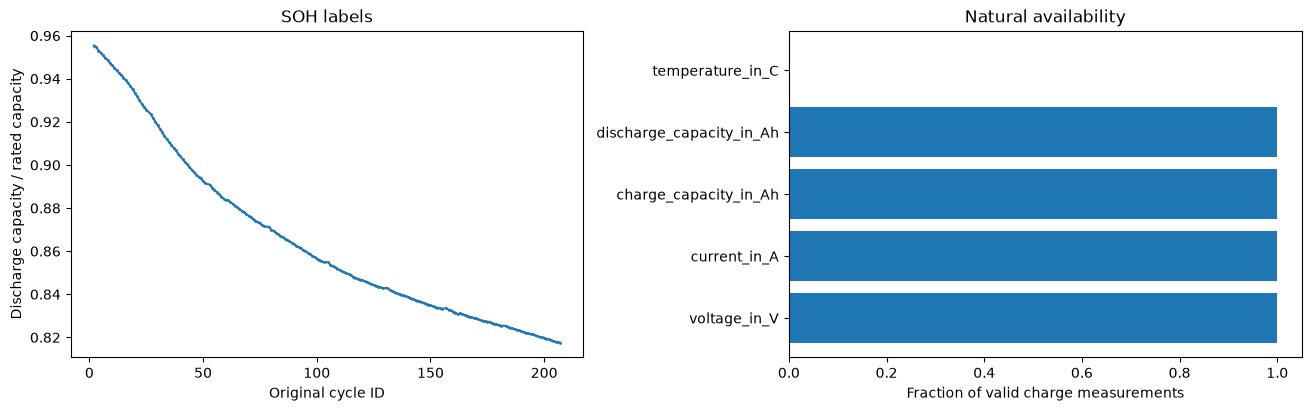

Static categorical IDs: [1, 1, 1, 0, 0]
Static numeric values: {'nominal_capacity_in_Ah': 3.5, 'max_voltage_limit_in_V': 4.199999809265137, 'min_voltage_limit_in_V': 2.6500000953674316}
Static validity: {'form_factor': True, 'cathode_material': True, 'anode_material': True, 'electrolyte_material': False, 'separator_material': False, 'nominal_capacity_in_Ah': True, 'max_voltage_limit_in_V': True, 'min_voltage_limit_in_V': True}
Cycle IDs are not renumbered; gaps: 7


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
valid_soh = cell["soh_valid"]
axes[0].plot(cell["cycle_id"][valid_soh], cell["soh"][valid_soh], ".-", markersize=2)
axes[0].set(
    xlabel="Original cycle ID",
    ylabel="Discharge capacity / rated capacity",
    title="SOH labels",
)
axes[1].barh(features, cell["value_valid"].mean(axis=0))
axes[1].set(
    xlim=(0, 1.05),
    xlabel="Fraction of valid charge measurements",
    title="Natural availability",
)
plt.show()
print("Static categorical IDs:", cell["static_categorical"].tolist())
print(
    "Static numeric values:",
    dict(zip(schema["static_numeric"], cell["static_numeric"].tolist())),
)
print(
    "Static validity:",
    dict(zip(schema["static_valid_order"], cell["static_valid"].tolist())),
)
print(
    "Cycle IDs are not renumbered; gaps:",
    int(np.count_nonzero(np.diff(cell["cycle_id"]) != 1)),
)


## 4. Dataset 的动态采样和 batch padding

每个样本先选锚点 k（最多第 100 轮），必须包含 k 的片段，再选择更早的循环。每轮随机裁一个连续充电片段；未来标签按真实循环编号 k+1...k+H 对齐。

默认 `channel_mask_probability=0`，仅随机选择循环数、片段位置和长度。`deterministic=False` 时，同一索引可以获得不同视图。它们仍来自同一电芯，不是独立电芯样本。

`segment_bounds` 是处理后充电数组中的左闭右开下标；`raw_sample_index` 可回查原始完整循环。

In [ ]:
dataset = TongjiDataset(
    DATA,
    cell_ids=[cell_id],
    samples_per_cell=16,
    history_cycles=(1, 6),
    segment_points=(8, 96),
    horizon=32,
    max_anchor_cycle=100,
    channel_mask_probability=0.0,
    seed=seed,
)
a, b = dataset[0], dataset[0]
for name, sample in [("view A", a), ("view B", b)]:
    print(
        name,
        "anchor",
        sample["anchor_cycle"],
        "cycles",
        sample["cycle_id"].tolist(),
        "lengths",
        [len(v) for v in sample["values"]],
    )
loader = DataLoader(
    dataset, batch_size=4, shuffle=False, num_workers=0, collate_fn=collate_tongji
)
batch = next(iter(loader))
for key, value in batch.items():
    print(
        f"{key:24}",
        tuple(value.shape) if torch.is_tensor(value) else value,
        value.dtype if torch.is_tensor(value) else "",
    )
print("Real points:", batch["point_valid"].sum().item())
print("Padding points:", (~batch["point_valid"]).sum().item())
print("Selected cycle IDs:\n", batch["cycle_id"])
print("Segment bounds:\n", batch["segment_bounds"])
assert not batch["value_valid"][~batch["point_valid"]].any()
assert not batch["value_visible"][~batch["point_valid"]].any()
assert torch.isfinite(batch["values"]).all()

view A anchor 49 cycles [2, 31, 40, 49] lengths [76, 84, 64, 14]
view B anchor 5 cycles [4, 5] lengths [50, 88]
cell_id                  ['Tongji1_CY45-05_1--6', 'Tongji1_CY45-05_1--6', 'Tongji1_CY45-05_1--6', 'Tongji1_CY45-05_1--6'] 
values                   (4, 4, 93, 5) torch.float32
value_valid              (4, 4, 93, 5) torch.bool
value_visible            (4, 4, 93, 5) torch.bool
point_valid              (4, 4, 93) torch.bool
time_in_cycle            (4, 4, 93) torch.float64
raw_sample_index         (4, 4, 93) torch.int64
cycle_id                 (4, 4) torch.int64
segment_bounds           (4, 4, 2) torch.int64
cycle_valid              (4, 4) torch.bool
history_cycle_id         (4, 75) torch.int64
history_u                (4, 75, 4) torch.float32
history_u_valid          (4, 75, 4) torch.bool
static_categorical       (4, 5) torch.int64
static_numeric           (4, 3) torch.float32
static_valid             (4, 8) torch.bool
future_u                 (4, 32, 4) torch.float32
future_u

## 5. 可视化三种标记与实际被选中的片段

四种颜色分别表示 PAD、天然缺失 UNK、人工遮蔽和可见测量。默认不进行人工通道遮蔽，因此通常不会出现蓝色。温度缺失会显示为 UNK；padding 必须显示为 PAD。

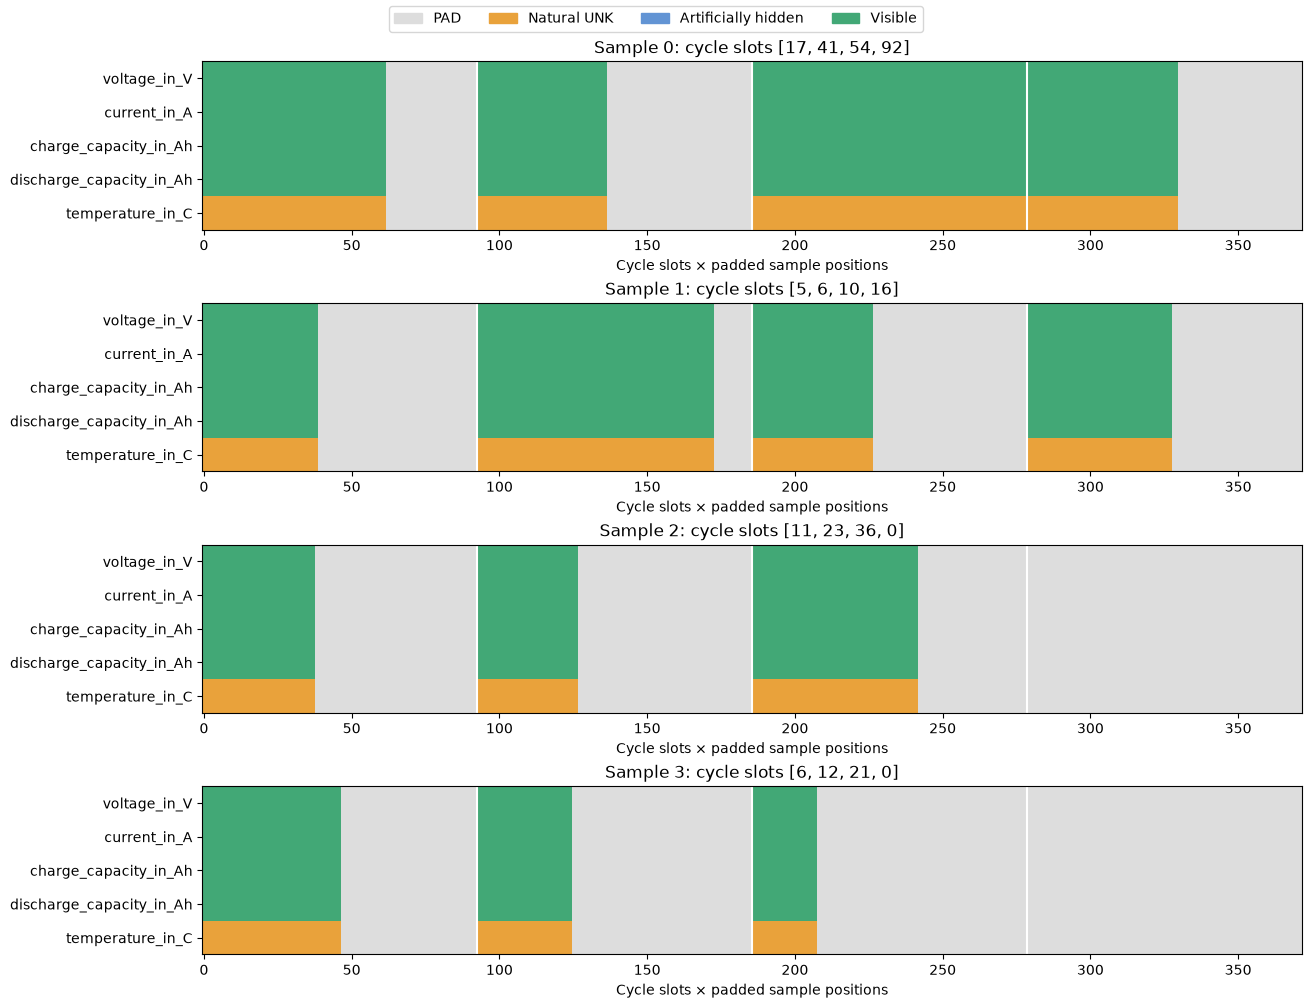

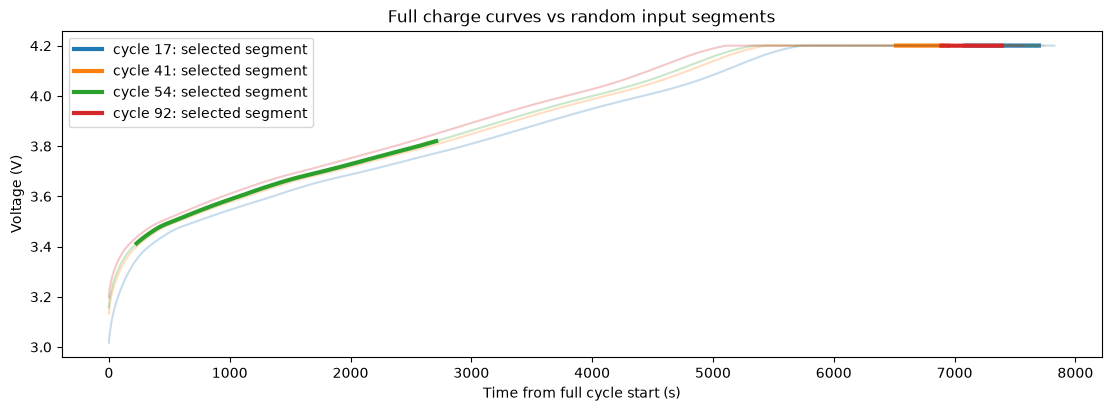

In [ ]:
def plot_masks(batch):
    point = batch["point_valid"].numpy()
    valid = batch["value_valid"].numpy()
    visible = batch["value_visible"].numpy()
    status = np.zeros(valid.shape, dtype=int)
    status[point[..., None] & ~valid] = 1
    status[point[..., None] & valid & ~visible] = 2
    status[point[..., None] & valid & visible] = 3
    colors = ["#dddddd", "#e9a23b", "#6294d4", "#42a876"]
    cmap = ListedColormap(colors)
    fig, axes = plt.subplots(
        len(point), 1, figsize=(13, 2.5 * len(point)), constrained_layout=True
    )
    for i, ax in enumerate(np.atleast_1d(axes)):
        image = status[i].reshape(-1, len(features)).T
        ax.imshow(
            image,
            aspect="auto",
            interpolation="nearest",
            cmap=cmap,
            norm=BoundaryNorm(np.arange(-0.5, 4.5), 4),
        )
        ax.set_yticks(range(len(features)), features)
        width = point.shape[-1]
        for boundary in range(1, point.shape[1]):
            ax.axvline(boundary * width - 0.5, color="white")
        ax.set_title(f"Sample {i}: cycle slots {batch['cycle_id'][i].tolist()}")
        ax.set_xlabel("Cycle slots × padded sample positions")
    fig.legend(
        handles=[
            Patch(color=c, label=l)
            for c, l in zip(
                colors, ["PAD", "Natural UNK", "Artificially hidden", "Visible"]
            )
        ],
        loc="outside upper center",
        ncol=4,
    )
    plt.show()


plot_masks(batch)

fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for j in range(int(batch["cycle_valid"][0].sum())):
    cid = int(batch["cycle_id"][0, j])
    row_j = int(np.searchsorted(cell["cycle_id"], cid))
    lo, hi = cell["cycle_offsets"][row_j : row_j + 2]
    (line,) = ax.plot(
        cell["time_in_cycle"][lo:hi], cell["values"][lo:hi, 0], alpha=0.25
    )
    used = batch["point_valid"][0, j]
    ax.plot(
        batch["time_in_cycle"][0, j, used],
        batch["values"][0, j, used, 0],
        linewidth=3,
        color=line.get_color(),
        label=f"cycle {cid}: selected segment",
    )
ax.set(
    xlabel="Time from full cycle start (s)",
    ylabel="Voltage (V)",
    title="Full charge curves vs random input segments",
)
ax.legend()
plt.show()


## 6. 未来标签、工况和 masked MSE 示例

未来工况来自已知的固定协议，包括未记录循环；未来测量曲线不进入输入。标签缺少的真实循环编号显示为无效，而不是把下一条存储记录错当作下一轮。超出记录范围也保持无效。

下面的常数预测仅用于演示损失的有效性标记和梯度，不是训练模型。每个样本先按有效标签数归一化。

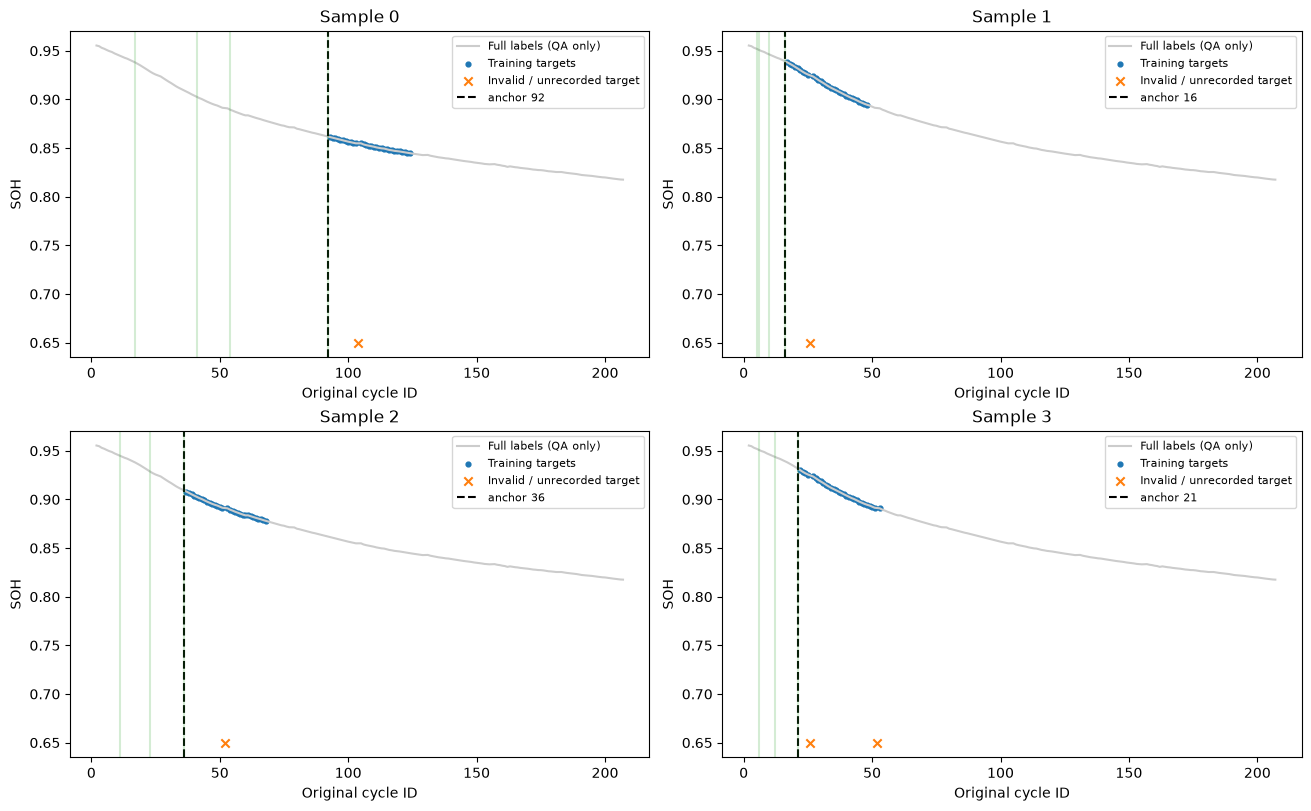

Future protocol for sample 0: {'ambient_temperature_in_C': 45.0, 'charge_rate_in_C': 0.5, 'discharge_rate_in_C': 1.0, 'post_charge_rest_in_s': 1800.0}
Future protocol valid: [True, True, True, True]


Demonstration masked trajectory MSE: 0.0007656938396394253


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for i, ax in enumerate(axes.flat):
    valid = batch["target_valid"][i]
    k = int(batch["anchor_cycle"][i])
    ax.plot(
        cell["cycle_id"][valid_soh],
        cell["soh"][valid_soh],
        color="0.8",
        label="Full labels (QA only)",
    )
    ax.scatter(
        batch["target_cycle_id"][i, valid],
        batch["target_soh"][i, valid],
        s=12,
        label="Training targets",
    )
    missing_ids = batch["target_cycle_id"][i, ~valid]
    if len(missing_ids):
        ax.scatter(
            missing_ids,
            np.full(len(missing_ids), 0.65),
            marker="x",
            label="Invalid / unrecorded target",
        )
    ax.axvline(k, linestyle="--", color="black", label=f"anchor {k}")
    for cid in batch["cycle_id"][i, batch["cycle_valid"][i]]:
        ax.axvline(int(cid), color="tab:green", alpha=0.2)
    ax.set(xlabel="Original cycle ID", ylabel="SOH", title=f"Sample {i}")
    ax.legend(fontsize=8)
plt.show()
print(
    "Future protocol for sample 0:",
    dict(zip(schema["conditions"], batch["future_u"][0, 0].tolist())),
)
print("Future protocol valid:", batch["future_u_valid"][0, 0].tolist())

prediction = torch.full_like(batch["target_soh"], 0.9, requires_grad=True)
mask = batch["target_valid"]
per_sample = ((prediction - batch["target_soh"]).square() * mask).sum(-1) / mask.sum(
    -1
).clamp_min(1)
loss = per_sample.mean()
loss.backward()
assert torch.isfinite(prediction.grad).all()
assert (prediction.grad[~mask] == 0).all()
print("Demonstration masked trajectory MSE:", float(loss.detach()))


## 7. 可选：独立检查人工通道遮蔽与固定验证视图

第一版训练关闭通道遮蔽。这里为了人工审查，单独生成遮蔽示例，验证被隐藏数值已置零，天然有效性仍保留。验证集使用 `deterministic=True`，同一索引固定同一视图；真正泛化实验必须先按电芯划分。

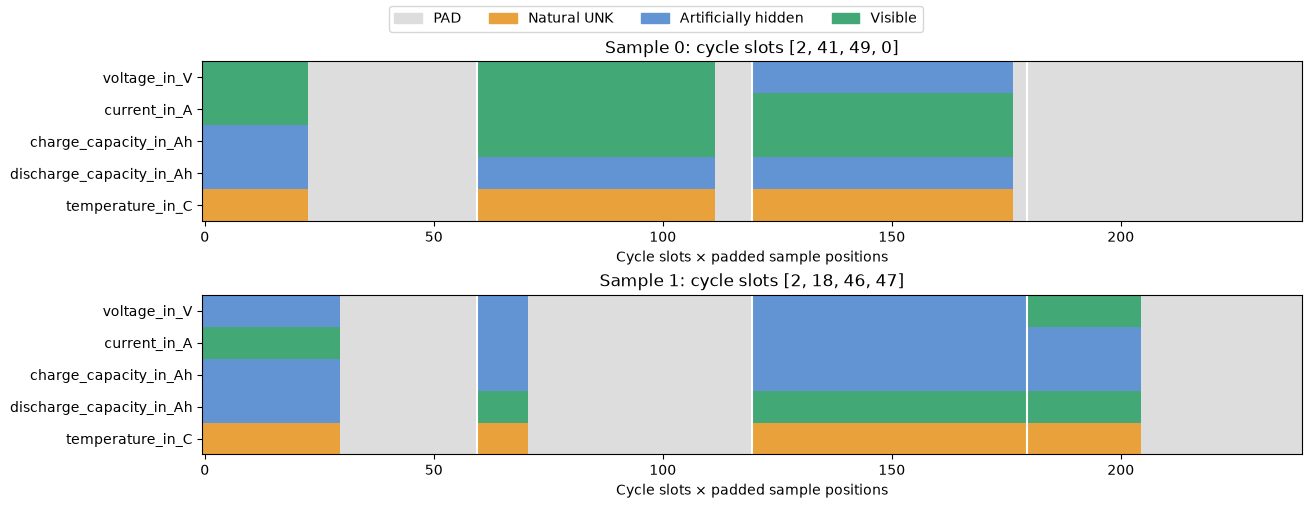

Hidden-value scrubbing and deterministic validation checks passed


In [ ]:
masked_dataset = TongjiDataset(
    DATA,
    cell_ids=[cell_id],
    history_cycles=(2, 4),
    segment_points=(8, 64),
    horizon=32,
    channel_mask_probability=0.5,
    seed=seed,
    deterministic=True,
)
masked_batch = collate_tongji([masked_dataset[i] for i in range(2)])
plot_masks(masked_batch)
hidden = masked_batch["point_valid"].unsqueeze(-1) & ~masked_batch["value_visible"]
assert (masked_batch["values"][hidden] == 0).all()
fixed_a, fixed_b = masked_dataset[0], masked_dataset[0]
assert torch.equal(fixed_a["cycle_id"], fixed_b["cycle_id"])
assert all(torch.equal(x, y) for x, y in zip(fixed_a["values"], fixed_b["values"]))
print("Hidden-value scrubbing and deterministic validation checks passed")

## 原 Notebook 探索代码留档

下面保留原先四个单元的源代码，方便追溯；其读取字段、统计循环的用途已包含在上面的审查流程中。

```python
import pickle
from pathlib import Path
```

```python
files = []
for filepath in Path("raw_data/Tongji").iterdir():
    # count how many Tongji1, Tongji2, Tongji3
    if filepath.name.startswith("Tongji1"):
        files.append(filepath)
```

```python
with open(files[0], "rb") as f:
    battery = pickle.load(f)

# print all keys in battery
print(battery.keys())
```

```python
# form_factor: battery shape
# anode_material
# cathode_material
# electrolyte_material
# nominal_capacity_in_Ah
# charge_protocol: {rate_in_C, current_in_A, voltage_in_V, power_in_W, start_voltage_in_V, start_soc, end_voltage_in_V, end_soc}

# cycle_data: list of dict, each dict contains:
# cycle_number
# current_in_A: numpy array item, list[ndarray]
# voltage_in_V: numpy array item, list[ndarray]
# charge_capacity_in_Ah: numpy array item, list[ndarray]
# discharge_capacity_in_Ah: numpy array item, list[ndarray]
# time_in_s: numpy array item, list[ndarray]

# print length of current_in_A, voltage_in_V, charge_capacity_in_Ah, discharge_capacity_in_Ah, time_in_s for each cycle

# format:
# cycle_number: length(min, max)
# current_in_A, voltage_in_V, charge_capacity_in_Ah, discharge_capacity_in_Ah, time_in_s
for cycle in battery["cycle_data"]:
    print(
        f"{cycle['cycle_number']:>3}: "
        f"{len(cycle['current_in_A'])}({min(cycle['current_in_A']):.2f},{max(cycle['current_in_A']):.2f}), "
        f"{len(cycle['voltage_in_V'])}({min(cycle['voltage_in_V']):.2f},{max(cycle['voltage_in_V']):.2f}), "
        f"{len(cycle['charge_capacity_in_Ah'])}({min(cycle['charge_capacity_in_Ah']):.2f},{max(cycle['charge_capacity_in_Ah']):.2f}), "
        f"{len(cycle['discharge_capacity_in_Ah'])}({min(cycle['discharge_capacity_in_Ah']):.2f},{max(cycle['discharge_capacity_in_Ah']):.2f}), "
        f"{len(cycle['time_in_s'])}({min(cycle['time_in_s']):.2f},{max(cycle['time_in_s']):.2f})"
    )
```